In [1]:
import pandas as pd

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv")["label"]
attack_cat_test = pd.read_csv("../data/processed/attack_cat_test.csv")["attack_cat"]

print(X_train.shape, X_test.shape, y_test.shape, attack_cat_test.shape)

(51890, 63) (82332, 63) (82332,) (82332,)


In [2]:
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    max_samples=256,
    random_state=3005
)

model.fit(X_train)

,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",256
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",3005
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...om_state=3005)


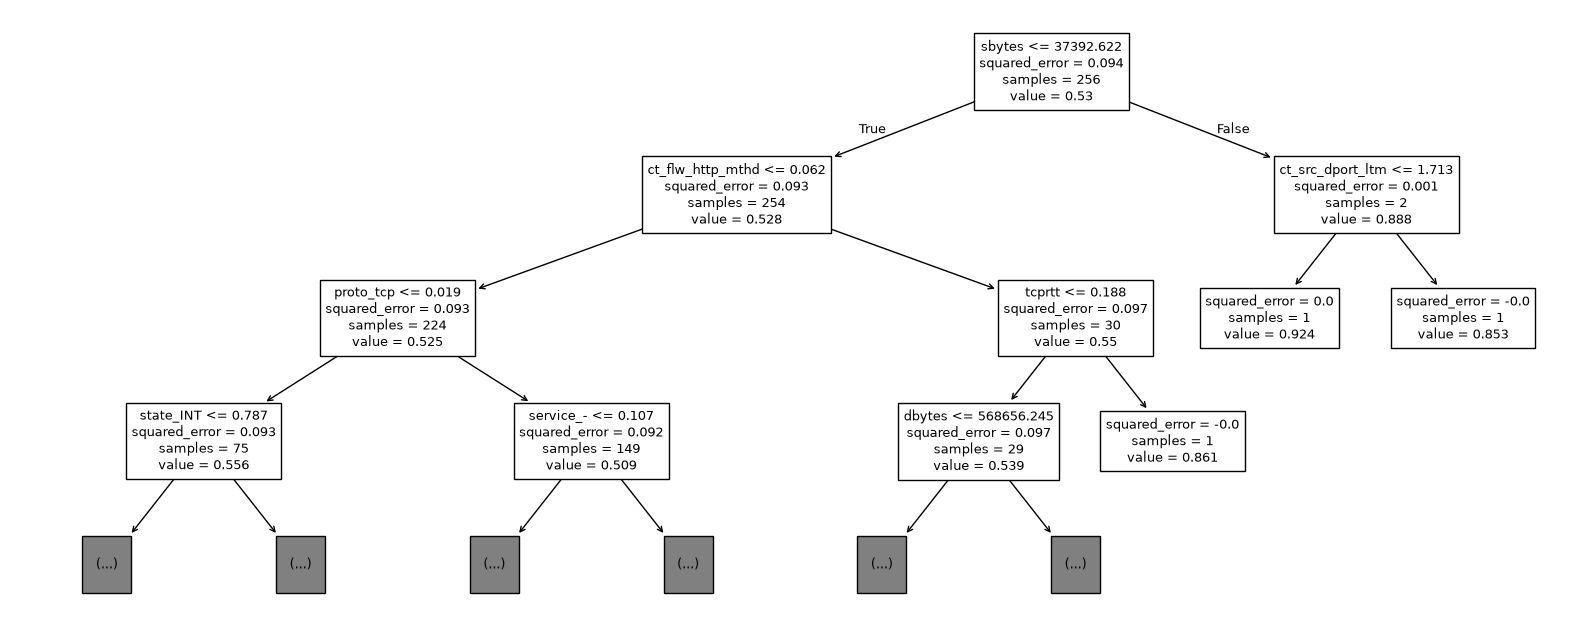

In [3]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 8))
plot_tree(
    model.estimators_[0],
    feature_names=list(X_train.columns),
    max_depth=3,
    filled=False,
    fontsize=9
)
plt.show()

In [4]:
scores = -model.score_samples(X_test)

print(scores[:10])
print(scores.min(), scores.max())

[0.48055383 0.5206623  0.51148077 0.4993533  0.53028781 0.5115686
 0.52744046 0.50243403 0.57283025 0.57283025]
0.3391052080560613 0.6537895552991454


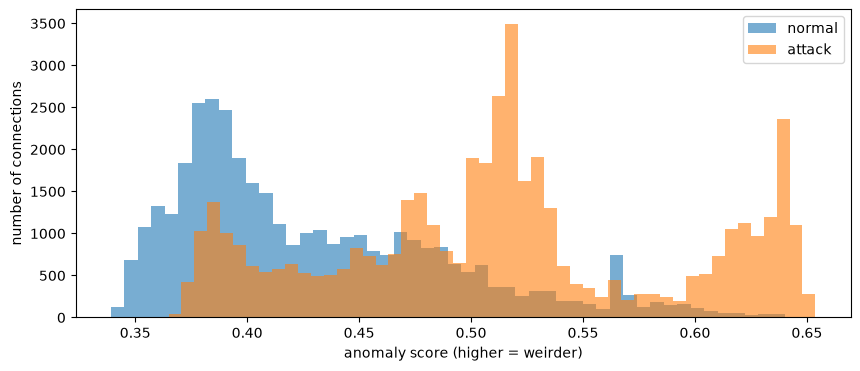

In [5]:
plt.figure(figsize=(10, 4))
plt.hist(scores[y_test == 0], bins=50, alpha=0.6, label='normal')
plt.hist(scores[y_test == 1], bins=50, alpha=0.6, label='attack')
plt.xlabel('anomaly score (higher = weirder)')
plt.ylabel('number of connections')
plt.legend()
plt.show()

In [6]:
train_scores = -model.score_samples(X_train)

threshold = pd.Series(train_scores).quantile(0.95)
print("Threshold:", threshold)

alerts = scores > threshold
print("Alerts raised:", alerts.sum(), "out of", len(scores))

Threshold: 0.5215128555768873
Alerts raised: 21245 out of 82332


In [11]:
pd.crosstab(y_test, alerts, rownames=['actual'], colnames=['alert'])

alert,False,True
actual,,
0,33458,3542
1,27629,17703


In [12]:
y = y_test.values

caught = ((y == 1) & alerts).sum()
missed = ((y == 1) & ~alerts).sum()
false_alarms = ((y == 0) & alerts).sum()
correctly_ignored = ((y == 0) & ~alerts).sum()

precision = caught / (caught + false_alarms)
recall = caught / (caught + missed)
fpr = false_alarms / (false_alarms + correctly_ignored)

print(f"Precision: {precision:.1%}")
print(f"Recall:    {recall:.1%}")
print(f"FPR:       {fpr:.1%}")

Precision: 83.3%
Recall:    39.1%
FPR:       9.6%
